# 02 - Customer-level Modelling Dataset and Churn Features

**Project:** Online Retail II - Customer Churn Prediction
**Role:** Data Engineering & Cleaning

| Task | Where |
|---|---|
| 2. Prepare the customer-level modelling dataset | Sections 4 - 7 |
| 3. Create the features required for churn prediction | Section 5 |
| 5. Ensure correct customer IDs and reference dates | Sections 2 - 3 |

**Input (from notebook 01):** `Working_Data/cleaned_transactions.csv.gz`, `Working_Data/cancelled_transactions.csv.gz`

**Output (folder `Working_Data`):** notebook 03 validates these and puts them into the one result file `Final_Result.xlsx`
- `Final_Modelling_Dataset.csv`: customer ID + reference date + features + churn target (for training and testing)
- `Feature_Dataset.csv`: customer ID + reference date + features only (no target)
- `Feature_Data_Dictionary.csv`: the meaning of every column

**Churn definition:** a customer **churns** if they place **no order in the 3 months after the reference date**.

## 1. Setup and load the verified transactions

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

WORK_DIR = 'Working_Data'
FINAL_DIR = WORK_DIR      # notebook 03 copies the validated datasets into Final_Result.xlsx
pd.set_option('display.max_colwidth', 120)

tx = pd.read_csv(f'{WORK_DIR}/cleaned_transactions.csv.gz', dtype={'Invoice': str, 'StockCode': str}, parse_dates=['InvoiceDate'])
cx = pd.read_csv(f'{WORK_DIR}/cancelled_transactions.csv.gz', dtype={'Invoice': str, 'StockCode': str}, parse_dates=['InvoiceDate'])
for t in (tx, cx):
    t['CustomerID'] = t['CustomerID'].astype('Int64')

print('Clean transactions :', len(tx))
print('Cancelled lines    :', len(cx))

Clean transactions : 1003338
Cancelled lines    : 17914


## 2. Customer IDs (task 5)

A churn model is built per customer, so only rows with a valid CustomerID can be used.
Guest sales (no CustomerID) are real revenue but cannot be linked to a customer.

In [2]:
guest_rows = tx['CustomerID'].isnull().sum()
known = tx.dropna(subset=['CustomerID']).copy()
known['CustomerID'] = known['CustomerID'].astype(int)
cancels = cx.dropna(subset=['CustomerID']).copy()
cancels['CustomerID'] = cancels['CustomerID'].astype(int)

print('Rows without CustomerID (excluded):', guest_rows, f'({guest_rows / len(tx) * 100:.1f}%)')
print('Rows with CustomerID               :', len(known))
print('Customers                          :', known['CustomerID'].nunique())
print('CustomerID range                   :', known['CustomerID'].min(), 'to', known['CustomerID'].max())
assert known['CustomerID'].between(10000, 99999).all(), 'Invalid CustomerID found'

Rows without CustomerID (excluded): 226761 (22.6%)
Rows with CustomerID               : 776577
Customers                          : 5852
CustomerID range                   : 12346 to 18287


In [3]:
# one row per order (invoice): the order date is the time of the invoice
orders = known.groupby(['CustomerID', 'Invoice']).agg(order_time=('InvoiceDate', 'min'),
                                                     revenue=('Revenue', 'sum'),
                                                     units=('Quantity', 'sum'),
                                                     country=('Country', 'first')).reset_index()
orders['order_date'] = orders['order_time'].dt.normalize()
known = known.merge(orders[['Invoice', 'order_time']], on='Invoice')        # each line gets its order's time
cancel_orders = cancels.groupby(['CustomerID', 'Invoice'])['InvoiceDate'].min().rename('cancel_time').reset_index()
print('Orders:', len(orders), '| cancelled orders:', len(cancel_orders))

Orders: 36592 | cancelled orders: 7282


## 3. Reference dates (task 5)

The **reference date** is the "today" of each row: features use only orders **before** it and the churn target uses only the
**3 months after** it.

- The data ends on **09-Dec-2011**, so December 2011 is a **partial month** and cannot be part of any target window.
- 83% of repeat orders happen within 90 days (transaction timeline review), so the target window is **3 months**.
- Features use a **12-month observation window** before the reference date.
- **4 reference dates, 3 months apart**, cover different seasons. The last one is kept as an **out-of-time test** sample.

In [4]:
OBSERVATION_MONTHS = 12
TARGET_MONTHS = 3
MIN_TENURE_DAYS = 30
TENURE_CAP_DAYS = 180          # feature stability check: tenure is only stable when capped at 180 days
REFERENCE_DATES = pd.to_datetime(['2010-12-01', '2011-03-01', '2011-06-01', '2011-09-01'])

data_start = known['InvoiceDate'].min().normalize()
data_end = known['InvoiceDate'].max().normalize()
first_partial_month = data_end.to_period('M').to_timestamp() if data_end.day < data_end.days_in_month else None

ref_table = pd.DataFrame({'reference_date': REFERENCE_DATES})
ref_table['sample'] = np.where(ref_table['reference_date'] == REFERENCE_DATES.max(), 'out_of_time_test', 'development')
ref_table['observation_start'] = ref_table['reference_date'] - pd.DateOffset(months=OBSERVATION_MONTHS)
ref_table['observation_end'] = ref_table['reference_date'] - pd.Timedelta(days=1)
ref_table['target_start'] = ref_table['reference_date']
ref_table['target_end'] = ref_table['reference_date'] + pd.DateOffset(months=TARGET_MONTHS) - pd.Timedelta(days=1)

print('Data range:', data_start.date(), 'to', data_end.date(), '| first partial month starts:', first_partial_month.date())
assert (ref_table['observation_start'] >= data_start).all(), 'An observation window starts before the data'
assert (ref_table['target_end'] < first_partial_month).all(), 'A target window goes into the partial month'
assert (ref_table['reference_date'].dt.day == 1).all(), 'Reference dates must be the 1st of a month'
ref_table

Data range: 2009-12-01 to 2011-12-09 | first partial month starts: 2011-12-01


,reference_date,sample,observation_start,observation_end,target_start,target_end
0,2010-12-01,development,2009-12-01,2010-11-30,2010-12-01,2011-02-28
1,2011-03-01,development,2010-03-01,2011-02-28,2011-03-01,2011-05-31
2,2011-06-01,development,2010-06-01,2011-05-31,2011-06-01,2011-08-31
3,2011-09-01,out_of_time_test,2010-09-01,2011-08-31,2011-09-01,2011-11-30


## 4. Eligible customers at each reference date

| Rule | Reason |
|---|---|
| First order before the reference date | The customer must exist on the reference date |
| At least 1 order in the 12-month observation window | Customers with no order for 12+ months have already left (a win-back problem, not churn prediction) |
| First order at least 30 days before the reference date | Too little history to describe the customer |

In [5]:
def eligible_customers(ref):
    obs_start = ref - pd.DateOffset(months=OBSERVATION_MONTHS)
    past = orders[orders['order_time'] < ref]
    first_order = past.groupby('CustomerID')['order_date'].min()
    in_obs = set(past.loc[past['order_time'] >= obs_start, 'CustomerID'])
    step1 = set(first_order.index)
    step2 = step1 & in_obs
    step3 = {c for c in step2 if (ref - first_order[c]).days >= MIN_TENURE_DAYS}
    counts = {'customers_seen_before_reference_date': len(step1),
              'removed_no_order_in_12_months': len(step1) - len(step2),
              f'removed_less_than_{MIN_TENURE_DAYS}_days_history': len(step2) - len(step3),
              'eligible_customers': len(step3)}
    return step3, counts

eligible, waterfall = {}, []
for ref in REFERENCE_DATES:
    eligible[ref], counts = eligible_customers(ref)
    waterfall.append({'reference_date': ref.date(), **counts})
waterfall = pd.DataFrame(waterfall)
waterfall

,reference_date,customers_seen_before_reference_date,removed_no_order_in_12_months,removed_less_than_30_days_history,eligible_customers
0,2010-12-01,4239,0,318,3921
1,2011-03-01,4512,252,128,4132
2,2011-06-01,4908,584,110,4214
3,2011-09-01,5224,901,95,4228


## 5. Churn features (task 3)

All features use **only orders before the reference date**. An order belongs to the period of its invoice time.

| Group | Features |
|---|---|
| Recency | `recency_days` |
| Frequency | `frequency_12m`, `orders_last_3m`, `orders_last_6m`, `active_months_12m`, `avg_days_between_orders_12m`, `is_one_time_buyer_12m` |
| Monetary | `monetary_12m`, `avg_order_value_12m`, `revenue_last_3m`, `units_12m` |
| Trend | `revenue_trend_ratio` (last 3 months vs the average 3 months) |
| Product | `distinct_products_12m` |
| Loyalty | `tenure_days_capped` |
| Returns | `cancelled_orders_12m`, `cancellation_rate_12m` |
| Seasonality | `orders_same_period_last_year` |
| Geography | `is_uk` |

In [6]:
def build_features(ref, customers):
    obs_start = ref - pd.DateOffset(months=OBSERVATION_MONTHS)
    past = orders[(orders['order_time'] < ref) & orders['CustomerID'].isin(customers)]
    obs = past[past['order_time'] >= obs_start]
    last3 = obs[obs['order_time'] >= ref - pd.DateOffset(months=3)]
    last6 = obs[obs['order_time'] >= ref - pd.DateOffset(months=6)]
    same_period = obs[obs['order_time'] < obs_start + pd.DateOffset(months=TARGET_MONTHS)]
    obs_lines = known[(known['order_time'] >= obs_start) & (known['order_time'] < ref) & known['CustomerID'].isin(customers)]
    obs_cancels = cancel_orders[(cancel_orders['cancel_time'] >= obs_start) & (cancel_orders['cancel_time'] < ref)]

    g = obs.groupby('CustomerID')
    f = pd.DataFrame(index=pd.Index(sorted(customers), name='customer_id'))
    f['recency_days'] = (ref - g['order_date'].max()).dt.days
    f['frequency_12m'] = g['Invoice'].nunique()
    f['orders_last_3m'] = last3.groupby('CustomerID')['Invoice'].nunique()
    f['orders_last_6m'] = last6.groupby('CustomerID')['Invoice'].nunique()
    f['active_months_12m'] = g['order_time'].apply(lambda s: s.dt.to_period('M').nunique())
    span_days = (g['order_date'].max() - g['order_date'].min()).dt.days
    f['avg_days_between_orders_12m'] = (span_days / (f['frequency_12m'] - 1)).where(f['frequency_12m'] > 1, 365.0).round(1)
    f['is_one_time_buyer_12m'] = (f['frequency_12m'] == 1).astype(int)
    f['monetary_12m'] = g['revenue'].sum().round(2)
    f['avg_order_value_12m'] = (f['monetary_12m'] / f['frequency_12m']).round(2)
    f['revenue_last_3m'] = last3.groupby('CustomerID')['revenue'].sum().round(2)
    f['units_12m'] = g['units'].sum()
    f['revenue_trend_ratio'] = (f['revenue_last_3m'].fillna(0) / (f['monetary_12m'] / 4)).round(3)
    f['distinct_products_12m'] = obs_lines.groupby('CustomerID')['StockCode'].nunique()
    first_order = past.groupby('CustomerID')['order_date'].min()
    f['tenure_days_capped'] = (ref - first_order).dt.days.clip(upper=TENURE_CAP_DAYS)
    f['cancelled_orders_12m'] = obs_cancels.groupby('CustomerID')['Invoice'].nunique()
    f['orders_same_period_last_year'] = same_period.groupby('CustomerID')['Invoice'].nunique()
    last_country = past.sort_values('order_time').groupby('CustomerID')['country'].last()
    f['is_uk'] = (last_country == 'United Kingdom').astype(int)

    zero_if_none = ['orders_last_3m', 'orders_last_6m', 'revenue_last_3m', 'cancelled_orders_12m', 'orders_same_period_last_year']
    f[zero_if_none] = f[zero_if_none].fillna(0)
    f['cancellation_rate_12m'] = (f['cancelled_orders_12m'] / (f['cancelled_orders_12m'] + f['frequency_12m'])).round(3)
    int_cols = ['recency_days', 'frequency_12m', 'orders_last_3m', 'orders_last_6m', 'active_months_12m', 'units_12m',
                'distinct_products_12m', 'tenure_days_capped', 'cancelled_orders_12m', 'orders_same_period_last_year']
    f[int_cols] = f[int_cols].astype(int)
    return f

FEATURES = ['recency_days', 'frequency_12m', 'orders_last_3m', 'orders_last_6m', 'active_months_12m',
            'avg_days_between_orders_12m', 'is_one_time_buyer_12m', 'monetary_12m', 'avg_order_value_12m',
            'revenue_last_3m', 'units_12m', 'revenue_trend_ratio', 'distinct_products_12m', 'tenure_days_capped',
            'cancelled_orders_12m', 'cancellation_rate_12m', 'orders_same_period_last_year', 'is_uk']
print('Number of features:', len(FEATURES))

Number of features: 18


## 6. Churn target

`churn_next_3m` = **1** if the customer places **no order** from the reference date to 3 months later, otherwise **0**.
It uses only orders inside that window.

In [7]:
def build_target(ref, customers):
    target_end = ref + pd.DateOffset(months=TARGET_MONTHS)
    window = orders[(orders['order_time'] >= ref) & (orders['order_time'] < target_end)]
    bought_again = set(window['CustomerID'])
    return pd.Series({c: 0 if c in bought_again else 1 for c in customers}, name='churn_next_3m').sort_index()

## 7. Build the final modelling dataset and the feature dataset (task 2)

In [8]:
parts = []
for ref in REFERENCE_DATES:
    f = build_features(ref, eligible[ref])[FEATURES]
    f['churn_next_3m'] = build_target(ref, eligible[ref])
    f = f.reset_index()
    f.insert(1, 'reference_date', ref.date())
    f.insert(2, 'sample', ref_table.loc[ref_table['reference_date'] == ref, 'sample'].iloc[0])
    parts.append(f)

modelling = pd.concat(parts, ignore_index=True)
modelling['reference_date'] = pd.to_datetime(modelling['reference_date'])
feature_dataset = modelling.drop(columns='churn_next_3m')

print('Final modelling dataset:', modelling.shape)
print('Feature dataset        :', feature_dataset.shape)
modelling.head()

Final modelling dataset: (16495, 22)
Feature dataset        : (16495, 21)


,customer_id,reference_date,sample,recency_days,frequency_12m,orders_last_3m,orders_last_6m,active_months_12m,avg_days_between_orders_12m,is_one_time_buyer_12m,...,revenue_last_3m,units_12m,revenue_trend_ratio,distinct_products_12m,tenure_days_capped,cancelled_orders_12m,cancellation_rate_12m,orders_same_period_last_year,is_uk,churn_next_3m
0,12346,2010-12-01,development,156,2,0,1,2,118.0,0,...,0.00,24,0.000,24,180,0,0.000,0,1,1
1,12347,2010-12-01,development,31,1,1,1,1,365.0,1,...,611.53,509,4.000,40,31,0,0.000,0,0,0
2,12348,2010-12-01,development,65,1,1,1,1,365.0,1,...,221.16,372,4.000,19,65,0,0.000,0,0,0
3,12349,2010-12-01,development,34,2,1,1,2,182.0,0,...,1152.62,991,2.076,89,180,1,0.333,0,0,1
4,12353,2010-12-01,development,35,1,1,1,1,365.0,1,...,317.76,192,4.000,20,35,0,0.000,0,0,1


In [9]:
summary_by_ref = modelling.groupby(['reference_date', 'sample']).agg(
    customers=('customer_id', 'count'),
    churn_rate_pct=('churn_next_3m', lambda s: round(s.mean() * 100, 1)),
    avg_recency_days=('recency_days', lambda s: round(s.mean(), 1)),
    avg_frequency_12m=('frequency_12m', lambda s: round(s.mean(), 2))).reset_index()
summary_by_ref

,reference_date,sample,customers,churn_rate_pct,avg_recency_days,avg_frequency_12m
0,2010-12-01,development,3921,66.2,93.5,4.54
1,2011-03-01,development,4132,62.8,125.5,4.32
2,2011-06-01,development,4214,63.3,134.0,4.20
3,2011-09-01,out_of_time_test,4228,50.4,147.2,4.16


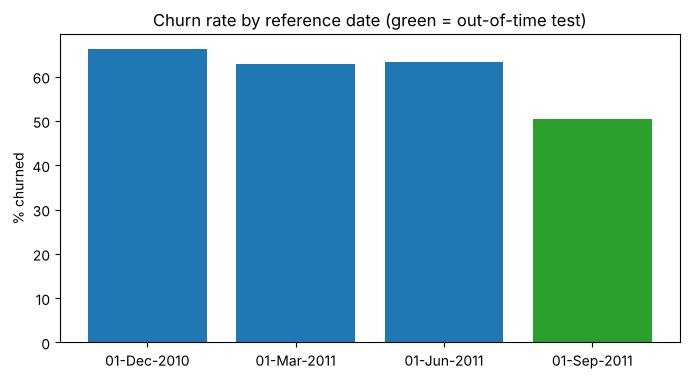

In [10]:
plt.figure(figsize=(8, 4))
plt.bar(summary_by_ref['reference_date'].dt.strftime('%d-%b-%Y'), summary_by_ref['churn_rate_pct'],
        color=['tab:blue', 'tab:blue', 'tab:blue', 'tab:green'])
plt.title('Churn rate by reference date (green = out-of-time test)')
plt.ylabel('% churned')
plt.show()

The out-of-time reference date (01-Sep-2011) has a **lower** churn rate because its target window (September to November)
is the Christmas buying season. Training on 3 reference dates from different seasons keeps the model from learning only one season.

In [11]:
modelling['recency_group'] = pd.cut(modelling['recency_days'], [0, 30, 90, 180, 365],
                                    labels=['0-30 days', '31-90 days', '91-180 days', '181-365 days'])
churn_by_recency = modelling.groupby('recency_group', observed=True)['churn_next_3m'].agg(['count', 'mean'])
churn_by_recency['mean'] = (churn_by_recency['mean'] * 100).round(1)
churn_by_recency.columns = ['rows', 'churn rate %']
modelling = modelling.drop(columns='recency_group')
churn_by_recency

,rows,churn rate %
recency_group,,
0-30 days,3714,33.3
31-90 days,4056,53.5
91-180 days,3806,69.1
181-365 days,4919,80.3


Customers who bought recently churn much less, so the features carry real signal for the model.

### 7.1 Quick checks before saving

The full, independent validation is in notebook **03 - Data Validation**.

In [12]:
assert modelling[['customer_id', 'reference_date']].duplicated().sum() == 0, 'Duplicate customer at a reference date'
assert modelling.isnull().sum().sum() == 0, 'Missing values found'
assert modelling['churn_next_3m'].isin([0, 1]).all(), 'Churn must be 0 or 1'
assert set(modelling['customer_id']) <= set(known['CustomerID']), 'Unknown customer ID'
assert (waterfall.set_index('reference_date')['eligible_customers'].values
        == modelling.groupby('reference_date').size().values).all(), 'Row counts do not match the eligibility counts'
print('Quick checks passed.')

Quick checks passed.


## 8. Save the datasets

In [13]:
data_dictionary = pd.DataFrame([
    ('customer_id', 'ID', '5-digit customer number'),
    ('reference_date', 'ID', 'The "today" of the row: features use orders before it, the target uses the 3 months after it'),
    ('sample', 'ID', 'development (train/validate) or out_of_time_test (final test on a later period)'),
    ('recency_days', 'Feature', 'Days from the last order to the reference date'),
    ('frequency_12m', 'Feature', 'Orders in the 12 months before the reference date'),
    ('orders_last_3m', 'Feature', 'Orders in the 3 months before the reference date'),
    ('orders_last_6m', 'Feature', 'Orders in the 6 months before the reference date'),
    ('active_months_12m', 'Feature', 'Months (out of 12) with at least one order'),
    ('avg_days_between_orders_12m', 'Feature', 'Average days between orders in the 12 months (365 if only 1 order)'),
    ('is_one_time_buyer_12m', 'Feature', '1 if the customer ordered only once in the 12 months'),
    ('monetary_12m', 'Feature', 'Money spent in the 12 months (GBP)'),
    ('avg_order_value_12m', 'Feature', 'monetary_12m / frequency_12m'),
    ('revenue_last_3m', 'Feature', 'Money spent in the 3 months before the reference date'),
    ('units_12m', 'Feature', 'Units bought in the 12 months'),
    ('revenue_trend_ratio', 'Feature', 'revenue_last_3m / (monetary_12m / 4): above 1 = spending more than usual, below 1 = spending less'),
    ('distinct_products_12m', 'Feature', 'Different products bought in the 12 months'),
    ('tenure_days_capped', 'Feature', f'Days since the first order, capped at {TENURE_CAP_DAYS} (stable across reference dates)'),
    ('cancelled_orders_12m', 'Feature', 'Cancelled orders in the 12 months'),
    ('cancellation_rate_12m', 'Feature', 'cancelled_orders_12m / (cancelled_orders_12m + frequency_12m)'),
    ('orders_same_period_last_year', 'Feature', 'Orders in the same 3 months one year before the target window'),
    ('is_uk', 'Feature', '1 if the country of the last order is the United Kingdom'),
    ('churn_next_3m', 'Target', '1 = no order in the 3 months after the reference date (churned), 0 = ordered again'),
], columns=['column', 'type', 'meaning'])

modelling.to_csv(f'{FINAL_DIR}/Final_Modelling_Dataset.csv', index=False, date_format='%Y-%m-%d')
feature_dataset.to_csv(f'{FINAL_DIR}/Feature_Dataset.csv', index=False, date_format='%Y-%m-%d')
data_dictionary.to_csv(f'{FINAL_DIR}/Feature_Data_Dictionary.csv', index=False)
waterfall.to_csv(f'{WORK_DIR}/eligibility_waterfall.csv', index=False)
ref_table.to_csv(f'{WORK_DIR}/reference_dates.csv', index=False, date_format='%Y-%m-%d')

assert list(data_dictionary['column']) == list(modelling.columns), 'Data dictionary does not match the columns'
for file, table in {f'{FINAL_DIR}/Final_Modelling_Dataset.csv': modelling, f'{FINAL_DIR}/Feature_Dataset.csv': feature_dataset,
                    f'{FINAL_DIR}/Feature_Data_Dictionary.csv': data_dictionary,
                    f'{WORK_DIR}/eligibility_waterfall.csv': waterfall, f'{WORK_DIR}/reference_dates.csv': ref_table}.items():
    saved = pd.read_csv(file)
    assert saved.shape == table.shape, f'{file} is wrong'
    print(f'{file}: {saved.shape[0]} rows x {saved.shape[1]} columns - OK')

Working_Data/Final_Modelling_Dataset.csv: 16495 rows x 22 columns - OK
Working_Data/Feature_Dataset.csv: 16495 rows x 21 columns - OK
Working_Data/Feature_Data_Dictionary.csv: 22 rows x 3 columns - OK
Working_Data/eligibility_waterfall.csv: 4 rows x 5 columns - OK
Working_Data/reference_dates.csv: 4 rows x 6 columns - OK


## 9. Summary

| Item | Result |
|---|---|
| Customers with a valid 5-digit ID | 5,852 (226,761 guest rows excluded) |
| Reference dates | 01-Dec-2010, 01-Mar-2011, 01-Jun-2011 (development) and 01-Sep-2011 (out-of-time test) |
| Windows | 12-month observation before each reference date, 3-month churn window after it; none touches the partial December 2011 |
| Eligible customers | 3,921 + 4,132 + 4,214 + 4,228 = **16,495 rows** (5,129 different customers) |
| Features | **18** churn features in 9 groups (recency, frequency, monetary, trend, product, loyalty, returns, seasonality, geography) |
| Churn rate | 66.2%, 62.8%, 63.3% (development, 64.0% overall) and 50.4% (out-of-time, Christmas season) |
| Signal check | Churn 33.3% for customers who ordered in the last 30 days vs 80.3% for 181-365 days |

**Saved:** `Working_Data/Final_Modelling_Dataset.csv` (16,495 x 22), `Working_Data/Feature_Dataset.csv` (16,495 x 21),
`Working_Data/Feature_Data_Dictionary.csv`. Notebook 03 validates them and puts them into `Final_Result.xlsx`.

Note: the out-of-time reference date (01-Sep-2011) has 4,228 customers, against 4,221 in the earlier modelling base, because the
30-day history rule now counts whole calendar days.

In [14]:
facts = [('Customers with ID', 5852, known['CustomerID'].nunique()), ('Guest rows', 226761, int(guest_rows)),
         ('Reference dates', 4, len(REFERENCE_DATES)),
         ('Eligible Dec-2010', 3921, len(eligible[REFERENCE_DATES[0]])), ('Eligible Mar-2011', 4132, len(eligible[REFERENCE_DATES[1]])),
         ('Eligible Jun-2011', 4214, len(eligible[REFERENCE_DATES[2]])), ('Eligible Sep-2011', 4228, len(eligible[REFERENCE_DATES[3]])),
         ('Rows', 16495, len(modelling)), ('Different customers', 5129, modelling['customer_id'].nunique()),
         ('Features', 18, len(FEATURES)),
         ('Churn Dec-2010', 66.2, summary_by_ref['churn_rate_pct'].iloc[0]), ('Churn Mar-2011', 62.8, summary_by_ref['churn_rate_pct'].iloc[1]),
         ('Churn Jun-2011', 63.3, summary_by_ref['churn_rate_pct'].iloc[2]), ('Churn Sep-2011', 50.4, summary_by_ref['churn_rate_pct'].iloc[3]),
         ('Development churn', 64.0, round(modelling.loc[modelling['sample'] == 'development', 'churn_next_3m'].mean() * 100, 1)),
         ('Churn 0-30 days', 33.3, churn_by_recency.loc['0-30 days', 'churn rate %']),
         ('Churn 181-365 days', 80.3, churn_by_recency.loc['181-365 days', 'churn rate %']),
         ('Modelling dataset shape', (16495, 22), modelling.shape), ('Feature dataset shape', (16495, 21), feature_dataset.shape)]
facts = pd.DataFrame(facts, columns=['Item', 'Reported', 'Notebook output'])
facts['Match'] = facts['Reported'].astype(str) == facts['Notebook output'].astype(str)
print('Summary numbers matching the outputs:', facts['Match'].sum(), 'out of', len(facts))
assert facts['Match'].all()
facts

Summary numbers matching the outputs: 19 out of 19


,Item,Reported,Notebook output,Match
0,Customers with ID,5852,5852,True
1,Guest rows,226761,226761,True
2,Reference dates,4,4,True
3,Eligible Dec-2010,3921,3921,True
4,Eligible Mar-2011,4132,4132,True
5,Eligible Jun-2011,4214,4214,True
6,Eligible Sep-2011,4228,4228,True
7,Rows,16495,16495,True
8,Different customers,5129,5129,True
9,Features,18,18,True
